# Week 7 homework — Blood-cell classification

**Machine Learning for Bioinformatics**

This notebook implements homework item 1 from Practical 7, Part VI:

> Inspect class balance and image properties, train the baseline CNN, and compare it with **one** controlled architecture change and **one** biologically valid augmentation strategy.

It follows the classification pipeline in `Practical_07_CNN_CVAT_YOLO_Cellpose.ipynb` (Parts I–III), but only the experiments the assignment asks for.

| Step | What we do | Why it is required |
|---|---|---|
| 1 | Inspect file type, shape, channels, dtype, intensity | Unsafe inputs break later transforms |
| 2 | Check class balance and a thumbnail t-SNE | Know whether classes are separable / imbalanced before modelling |
| 3 | Make a **fixed** stratified split | Later comparisons must not be caused by a different split |
| 4 | Train the baseline CNN | The reference model |
| 5 | Change **one** architectural factor | Controlled experiment |
| 6 | Train with a biologically valid augmentation | Labels must stay meaningful after the transform |
| 7 | Compare metrics on the same validation/test split | Assignment report questions 1, 2 and 6 |

VGG16 transfer learning and the full six-variant architecture sweep from the practical are **not** required here.


## 0. Setup

`RANDOM_STATE` is fixed so the train/validation/test split is identical for the baseline, the architecture change, and the augmentation comparison. That is how we answer report question 2.

Set `RUN_DATA_DOWNLOAD=True` once to fetch the Kaggle blood-cell dataset. Set `RUN_EXPENSIVE=True` when you actually want to train (Colab GPU recommended).


In [ ]:
from pathlib import Path
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from IPython.display import display

RANDOM_STATE = 221026
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
RUN_DATA_DOWNLOAD = True
RUN_EXPENSIVE = True
SHOW_PLOTS = True
IMAGE_SIZE = 128
BATCH_SIZE = 32
BASELINE_EPOCHS = 10
COMPARISON_EPOCHS = 10  # same budget as the baseline so the split is the only shared factor

print('PyTorch:', torch.__version__)
print('Device:', DEVICE)


PyTorch: 2.14.1+cpu
Device: cpu


## 1. Locate week 7 and download the blood-cell dataset

The dataset is [unclesamulus/blood-cells-image-dataset](https://www.kaggle.com/datasets/unclesamulus/blood-cells-image-dataset). We discover the `ImageFolder` root after download instead of assuming a fixed folder name or class count: each immediate subfolder becomes one class label.


In [ ]:
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp'}


def locate_week7_root():
    current = Path.cwd().resolve()
    for base in (current, *current.parents):
        for candidate in (base, base / 'week7'):
            if (candidate / 'detection').is_dir() and any(
                (candidate / name).is_dir() for name in ('segemntation', 'segmentation')
            ):
                return candidate
    return current


WEEK7_ROOT = locate_week7_root()
CLASSIFICATION_CACHE = WEEK7_ROOT / 'classification'
print('WEEK7_ROOT:', WEEK7_ROOT)

classification_download = None
if RUN_DATA_DOWNLOAD:
    import kagglehub
    classification_download = Path(kagglehub.dataset_download('unclesamulus/blood-cells-image-dataset'))
    print('Kaggle path:', classification_download)
else:
    print('Download skipped. Set RUN_DATA_DOWNLOAD=True if the dataset is not already cached.')


def has_imagefolder_classes(directory):
    if not directory.is_dir():
        return False
    class_dirs = [child for child in directory.iterdir() if child.is_dir()]
    return len(class_dirs) >= 2 and all(
        any(file.suffix.lower() in IMAGE_EXTENSIONS for file in child.iterdir())
        for child in class_dirs
    )


def find_imagefolder_root(root):
    candidates = [root] + sorted(path for path in root.rglob('*') if path.is_dir())
    valid = [path for path in candidates if has_imagefolder_classes(path)]
    if not valid:
        return None
    return max(valid, key=lambda path: len(list(path.iterdir())))


classification_candidates = [
    path for path in (classification_download, CLASSIFICATION_CACHE)
    if path is not None and Path(path).exists()
]
classification_root = next(
    (
        found for path in classification_candidates
        if (found := find_imagefolder_root(Path(path))) is not None
    ),
    None,
)
print('ImageFolder root:', classification_root)


WEEK7_ROOT: /content


100%|██████████| 268M/268M [00:02<00:00, 135MB/s]

Extracting files...


Kaggle path: /root/.cache/kagglehub/datasets/unclesamulus/blood-cells-image-dataset/versions/2
ImageFolder root: /root/.cache/kagglehub/datasets/unclesamulus/blood-cells-image-dataset/versions/2/bloodcells_dataset


## 2. Image-property inspection

Before modelling we treat the files as an imaging experiment: format, mode, spatial size, channel count, dtype and intensity range. A grayscale image must not silently become a fake 3-channel RGB image, and a 16-bit range must not be normalized as if it were 8-bit.


In [ ]:
def image_inventory_row(path, source):
    row = {'source': source, 'file': path.name, 'readable': False}
    try:
        with Image.open(path) as image:
            array = np.asarray(image)
            row.update({
                'readable': True,
                'format': image.format,
                'mode': image.mode,
                'width': image.width,
                'height': image.height,
                'array_shape': tuple(array.shape),
                'dtype': str(array.dtype),
                'channels': 1 if array.ndim == 2 else array.shape[-1],
                'min_intensity': float(np.nanmin(array)),
                'max_intensity': float(np.nanmax(array)),
                'finite': bool(np.isfinite(array).all()),
            })
    except Exception as error:
        row['error'] = repr(error)
    return row


if classification_root is None:
    image_inventory = pd.DataFrame()
    print('Classification data not found.')
else:
    inventory_rows = []
    for class_dir in sorted(path for path in classification_root.iterdir() if path.is_dir()):
        files = [path for path in class_dir.iterdir() if path.suffix.lower() in IMAGE_EXTENSIONS]
        for path in files[:3]:
            inventory_rows.append(image_inventory_row(path, class_dir.name))
    image_inventory = pd.DataFrame(inventory_rows)
    display(image_inventory)
    print('Unreadable files:', int((~image_inventory['readable']).sum()) if len(image_inventory) else 0)
    print('Unique modes:', sorted(image_inventory['mode'].dropna().unique().tolist()) if len(image_inventory) else [])
    print('Unique dtypes:', sorted(image_inventory['dtype'].dropna().unique().tolist()) if len(image_inventory) else [])


,source,file,readable,format,mode,width,height,array_shape,dtype,channels,min_intensity,max_intensity,finite
0,basophil,BA_347386.jpg,True,JPEG,RGB,360,363,"(363, 360, 3)",uint8,3,0.0,255.0,True
1,basophil,BA_677090.jpg,True,JPEG,RGB,360,363,"(363, 360, 3)",uint8,3,0.0,255.0,True
2,basophil,BA_124938.jpg,True,JPEG,RGB,360,363,"(363, 360, 3)",uint8,3,0.0,255.0,True
3,eosinophil,EO_630646.jpg,True,JPEG,RGB,360,363,"(363, 360, 3)",uint8,3,0.0,255.0,True
4,eosinophil,EO_197217.jpg,True,JPEG,RGB,360,363,"(363, 360, 3)",uint8,3,3.0,255.0,True
5,eosinophil,EO_248919.jpg,True,JPEG,RGB,360,363,"(363, 360, 3)",uint8,3,3.0,255.0,True
6,erythroblast,ERB_767994.jpg,True,JPEG,RGB,360,363,"(363, 360, 3)",uint8,3,8.0,255.0,True
7,erythroblast,ERB_174666.jpg,True,JPEG,RGB,360,363,"(363, 360, 3)",uint8,3,0.0,255.0,True
8,erythroblast,ERB_901868.jpg,True,JPEG,RGB,360,363,"(363, 360, 3)",uint8,3,6.0,255.0,True
9,ig,PMY_147025.jpg,True,JPEG,RGB,360,363,"(363, 360, 3)",uint8,3,0.0,255.0,True


Unreadable files: 0
Unique modes: ['RGB']
Unique dtypes: ['uint8']


## 3. Class balance and thumbnail t-SNE

Class counts tell us whether accuracy can be dominated by a majority class. The t-SNE is only an exploratory view: it uses small grayscale thumbnails, not the CNN representation, so it is not a performance estimate.


,images
neutrophil,3329
eosinophil,3117
ig,2895
platelet,2348
erythroblast,1551
monocyte,1420
basophil,1218
lymphocyte,1214


Total images: 17092
Imbalance ratio (max/min): 2.742174629324547


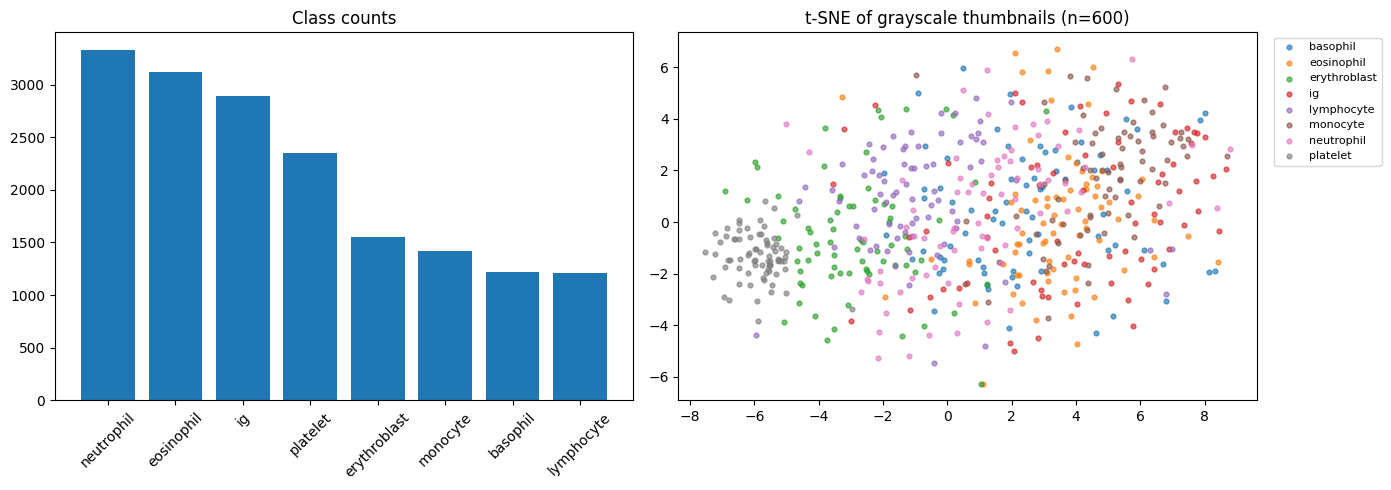

In [ ]:
if classification_root is None:
    image_dataset = None
    CLASS_NAMES = []
    print('EDA skipped.')
else:
    from sklearn.manifold import TSNE
    from sklearn.preprocessing import StandardScaler

    image_dataset = datasets.ImageFolder(classification_root)
    CLASS_NAMES = image_dataset.classes
    targets = np.asarray(image_dataset.targets)
    class_counts = pd.Series(
        {CLASS_NAMES[class_id]: int(np.sum(targets == class_id)) for class_id in range(len(CLASS_NAMES))},
        name='images',
    ).sort_values(ascending=False)
    display(class_counts.to_frame())
    print('Total images:', int(class_counts.sum()))
    print('Imbalance ratio (max/min):', float(class_counts.max() / max(1, class_counts.min())))

    eda_rng = np.random.default_rng(RANDOM_STATE)
    max_eda_images = 600
    per_class = max(1, max_eda_images // len(CLASS_NAMES))
    eda_indices = []
    for class_id in range(len(CLASS_NAMES)):
        class_indices = np.flatnonzero(targets == class_id)
        take = min(per_class, len(class_indices))
        eda_indices.extend(eda_rng.choice(class_indices, size=take, replace=False).tolist())

    eda_features, eda_labels = [], []
    for index in eda_indices:
        image_path, label = image_dataset.samples[index]
        with Image.open(image_path) as image:
            thumbnail = np.asarray(image.convert('L').resize((32, 32)), dtype=np.float32) / 255.0
        eda_features.append(thumbnail.ravel())
        eda_labels.append(label)
    eda_features = StandardScaler().fit_transform(np.asarray(eda_features))
    eda_labels = np.asarray(eda_labels)

    if SHOW_PLOTS and len(eda_features) >= 4:
        eda_perplexity = min(30, max(2, (len(eda_features) - 1) // 3))
        embedding = TSNE(
            n_components=2, perplexity=eda_perplexity, init='pca',
            learning_rate='auto', random_state=RANDOM_STATE,
        ).fit_transform(eda_features)
        figure, axes = plt.subplots(1, 2, figsize=(14, 5))
        axes[0].bar(class_counts.index, class_counts.values)
        axes[0].set_title('Class counts')
        axes[0].tick_params(axis='x', rotation=45)
        for class_id, class_name in enumerate(CLASS_NAMES):
            mask = eda_labels == class_id
            axes[1].scatter(embedding[mask, 0], embedding[mask, 1], s=12, alpha=0.65, label=class_name)
        axes[1].set_title(f't-SNE of grayscale thumbnails (n={len(eda_features)})')
        axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
        plt.tight_layout()
        plt.show()


## 4. What a convolution does to a cell image

A convolution kernel slides across the image and computes a weighted local sum. Hand-designed kernels make the later CNN less abstract: blur averages neighbours, Sobel-like kernels emphasise edges, sharpening emphasises local contrast. The CNN will learn its own kernels from the training labels.


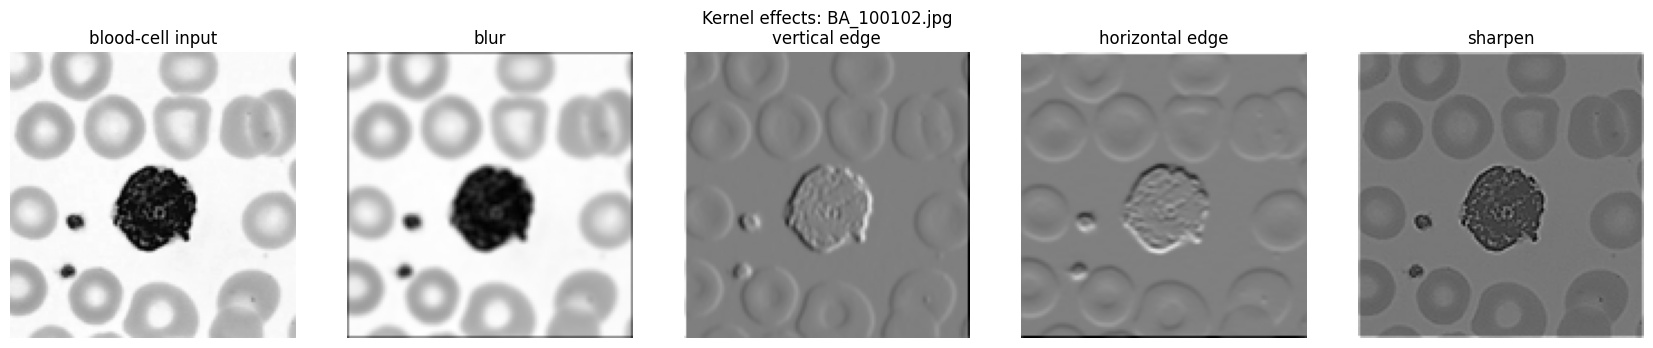

In [ ]:
if classification_root is not None and image_dataset is not None and len(image_dataset) > 0:
    kernel_source = Path(image_dataset.samples[0][0])
    demo_image = np.asarray(Image.open(kernel_source).convert('L').resize((128, 128)), dtype=np.float32) / 255.0
else:
    kernel_source = None
    yy, xx = np.mgrid[-1:1:128j, -1:1:128j]
    demo_image = np.exp(-((xx - 0.3) ** 2 + (yy + 0.1) ** 2) / 0.08)

kernels = {
    'blur': np.ones((3, 3), dtype=np.float32) / 9,
    'vertical edge': np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32),
    'horizontal edge': np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=np.float32),
    'sharpen': np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=np.float32),
}
input_tensor = torch.from_numpy(demo_image)[None, None]
filtered = {
    name: F.conv2d(input_tensor, torch.from_numpy(kernel)[None, None], padding=1)[0, 0].numpy()
    for name, kernel in kernels.items()
}

if SHOW_PLOTS:
    figure, axes = plt.subplots(1, 5, figsize=(17, 3.5))
    axes[0].imshow(demo_image, cmap='gray')
    axes[0].set_title('blood-cell input')
    for axis, (name, output) in zip(axes[1:], filtered.items()):
        axis.imshow(output, cmap='gray')
        axis.set_title(name)
    for axis in axes:
        axis.axis('off')
    figure.suptitle(f'Kernel effects: {kernel_source.name if kernel_source else "fallback"}')
    plt.tight_layout()
    plt.show()


## 5. Fixed split and deterministic baseline transforms

The baseline uses only resize + `ToTensor`. Random augmentation is introduced later as its own experiment, so any accuracy difference can be attributed to that change rather than being mixed into the baseline.

The split is stratified by class and frozen by `RANDOM_STATE`. Every later model reuses `train_indices`, `val_indices` and `test_indices`.


In [ ]:
base_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
])
eval_transform = base_transform

train_loader = val_loader = test_loader = None
classification_ready = classification_root is not None
train_indices = val_indices = test_indices = None

if classification_ready:
    image_dataset = datasets.ImageFolder(classification_root)
    CLASS_NAMES = image_dataset.classes
    targets = np.asarray(image_dataset.targets)
    indices = np.arange(len(image_dataset))
    train_indices, temporary_indices = train_test_split(
        indices, test_size=0.2, random_state=RANDOM_STATE, stratify=targets,
    )
    val_indices, test_indices = train_test_split(
        temporary_indices, test_size=0.5, random_state=RANDOM_STATE,
        stratify=targets[temporary_indices],
    )
    train_source = datasets.ImageFolder(classification_root, transform=base_transform)
    eval_source = datasets.ImageFolder(classification_root, transform=eval_transform)
    train_dataset = Subset(train_source, train_indices)
    val_dataset = Subset(eval_source, val_indices)
    test_dataset = Subset(eval_source, test_indices)
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    print('Classes:', CLASS_NAMES)
    print('Split sizes: train/val/test =', len(train_dataset), len(val_dataset), len(test_dataset))
    split_check = pd.DataFrame({
        'train': [int(np.sum(targets[train_indices] == class_id)) for class_id in range(len(CLASS_NAMES))],
        'val': [int(np.sum(targets[val_indices] == class_id)) for class_id in range(len(CLASS_NAMES))],
        'test': [int(np.sum(targets[test_indices] == class_id)) for class_id in range(len(CLASS_NAMES))],
    }, index=CLASS_NAMES)
    display(split_check)
else:
    print('Classification data are not available.')


Classes: ['basophil', 'eosinophil', 'erythroblast', 'ig', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']
Split sizes: train/val/test = 13673 1709 1710


,train,val,test
basophil,974,122,122
eosinophil,2494,311,312
erythroblast,1241,155,155
ig,2316,289,290
lymphocyte,971,122,121
monocyte,1136,142,142
neutrophil,2663,333,333
platelet,1878,235,235


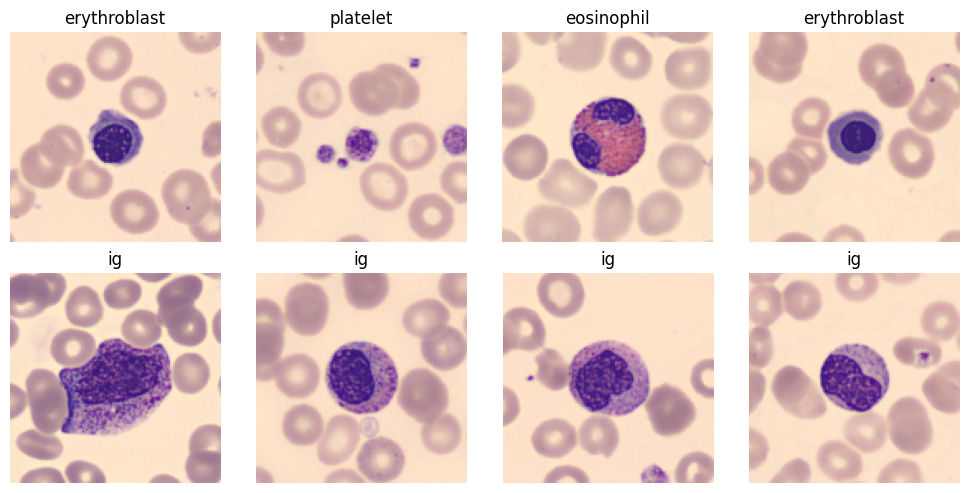

In [ ]:
if classification_ready and SHOW_PLOTS:
    batch_images, batch_labels = next(iter(train_loader))
    figure, axes = plt.subplots(2, 4, figsize=(10, 5))
    for axis, image, label in zip(axes.ravel(), batch_images[:8], batch_labels[:8]):
        axis.imshow(np.clip(image.permute(1, 2, 0).numpy(), 0, 1))
        axis.set_title(CLASS_NAMES[int(label)])
        axis.axis('off')
    plt.tight_layout()
    plt.show()


## 6. Baseline CNN

The classifier outputs one logit per class. `CrossEntropyLoss` expects logits, so we do not add a softmax before the loss. During prediction, `argmax` selects the class with the largest logit.

The baseline has two convolution–ReLU–pooling blocks, then a linear layer. This is the same `SimpleCNN` as in the practical.


In [ ]:
class SimpleCNN(nn.Module):
    def __init__(self, in_channels, n_classes, image_size=128):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_channels, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        reduced = image_size // 4
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * reduced * reduced, n_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def count_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, y_true, y_pred = 0.0, [], []
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * images.size(0)
        y_true.extend(labels.detach().cpu().numpy())
        y_pred.extend(logits.argmax(1).detach().cpu().numpy())
    return total_loss / len(loader.dataset), accuracy_score(y_true, y_pred)


@torch.no_grad()
def evaluate_classifier(model, loader, criterion, device):
    model.eval()
    total_loss, y_true, y_pred = 0.0, [], []
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        total_loss += criterion(logits, labels).item() * images.size(0)
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(logits.argmax(1).cpu().numpy())
    return total_loss / len(loader.dataset), accuracy_score(y_true, y_pred), np.asarray(y_true), np.asarray(y_pred)


def fit_classifier(model, train_loader, val_loader, epochs, lr=1e-3):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)
        val_loss, val_acc, _, _ = evaluate_classifier(model, val_loader, criterion, DEVICE)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        print(f'{epoch + 1:02d} | train={train_acc:.3f} | val={val_acc:.3f}')
    return history, criterion


model = None
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
if classification_ready:
    model = SimpleCNN(3, len(CLASS_NAMES), IMAGE_SIZE).to(DEVICE)
    print(model)
    print('Trainable parameters:', count_parameters(model))


SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=32768, out_features=8, bias=True)
  )
)
Trainable parameters: 267240


In [ ]:
if classification_ready and RUN_EXPENSIVE:
    history, criterion = fit_classifier(model, train_loader, val_loader, BASELINE_EPOCHS)
else:
    criterion = nn.CrossEntropyLoss()
    print('Baseline training skipped. Set RUN_EXPENSIVE=True to train.')


01 | train=0.602 | val=0.783
02 | train=0.837 | val=0.851
03 | train=0.870 | val=0.856
04 | train=0.893 | val=0.882
05 | train=0.911 | val=0.879
06 | train=0.926 | val=0.891
07 | train=0.938 | val=0.900
08 | train=0.948 | val=0.908
09 | train=0.952 | val=0.913
10 | train=0.964 | val=0.909


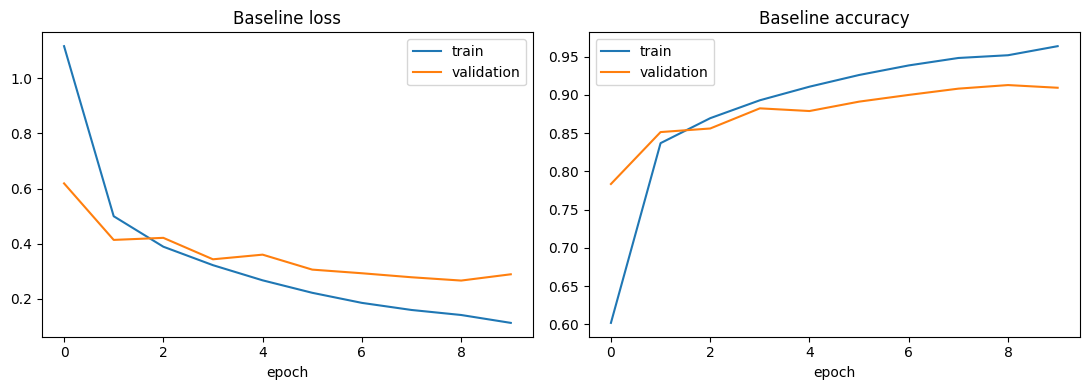

Baseline validation accuracy: 0.9093036863662961
Baseline test accuracy: 0.895906432748538
              precision    recall  f1-score   support

    basophil       0.90      0.85      0.88       122
  eosinophil       0.96      0.97      0.96       312
erythroblast       0.93      0.88      0.90       155
          ig       0.72      0.86      0.78       290
  lymphocyte       0.90      0.85      0.87       121
    monocyte       0.85      0.68      0.75       142
  neutrophil       0.94      0.93      0.94       333
    platelet       1.00      0.99      0.99       235

    accuracy                           0.90      1710
   macro avg       0.90      0.88      0.89      1710
weighted avg       0.90      0.90      0.90      1710



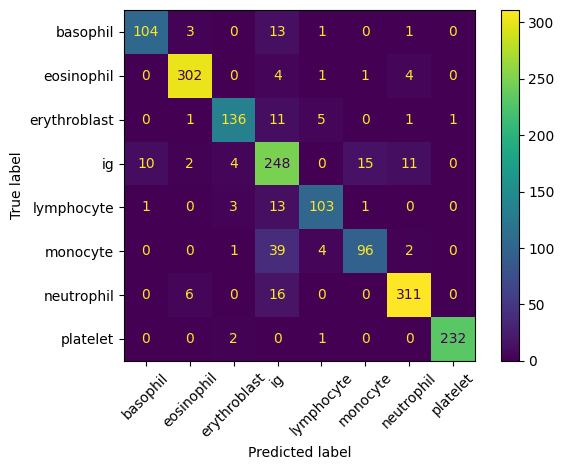

In [ ]:
if history['train_loss'] and SHOW_PLOTS:
    figure, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(history['train_loss'], label='train')
    axes[0].plot(history['val_loss'], label='validation')
    axes[0].set(title='Baseline loss', xlabel='epoch')
    axes[0].legend()
    axes[1].plot(history['train_acc'], label='train')
    axes[1].plot(history['val_acc'], label='validation')
    axes[1].set(title='Baseline accuracy', xlabel='epoch')
    axes[1].legend()
    plt.tight_layout()
    plt.show()

baseline_row = None
if classification_ready and RUN_EXPENSIVE:
    test_loss, test_acc, y_true, y_pred = evaluate_classifier(model, test_loader, criterion, DEVICE)
    _, val_acc, _, _ = evaluate_classifier(model, val_loader, criterion, DEVICE)
    print('Baseline validation accuracy:', val_acc)
    print('Baseline test accuracy:', test_acc)
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=CLASS_NAMES, xticks_rotation=45)
    plt.tight_layout()
    plt.show()
    baseline_row = {
        'model': 'baseline SimpleCNN',
        'change': 'none',
        'parameters': count_parameters(model),
        'epochs': BASELINE_EPOCHS,
        'val_accuracy': val_acc,
        'test_accuracy': test_acc,
    }
else:
    print('Baseline evaluation skipped.')


## 7. Learned feature maps

A forward hook records each `Conv2d` output. We display the channel with the largest spatial variance. Early maps often respond to edges or texture; later maps combine those patterns. If training was skipped, the maps only show tensor shapes.


Image: EO_361149.jpg
Predicted class: eosinophil


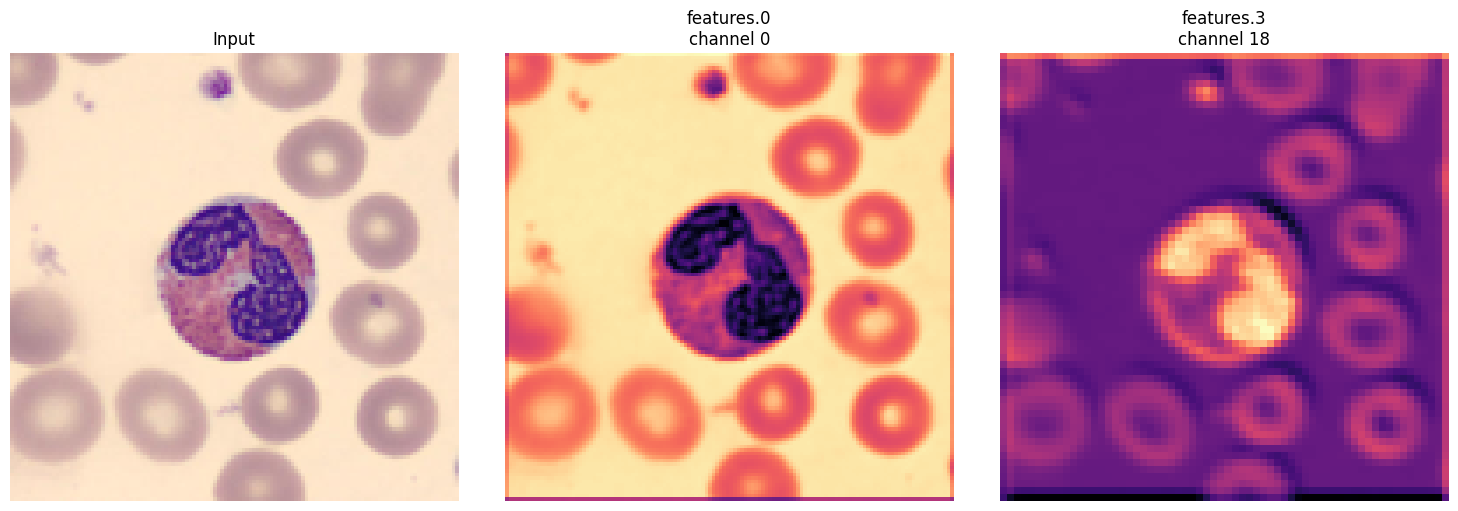

In [ ]:
learned_conv_activations = {}
if classification_ready and model is not None and len(image_dataset) > 0:
    activation_source = Path(image_dataset.samples[int(val_indices[0])][0])
    with Image.open(activation_source) as source_image:
        activation_image = source_image.convert('RGB')
        activation_tensor = eval_transform(activation_image).unsqueeze(0).to(DEVICE)
    hooks = []
    for layer_name, layer in model.named_modules():
        if isinstance(layer, nn.Conv2d):
            hooks.append(layer.register_forward_hook(
                lambda module, inputs, output, name=layer_name: learned_conv_activations.__setitem__(
                    name, output.detach().cpu()
                )
            ))
    model.eval()
    with torch.no_grad():
        activation_logits = model(activation_tensor)
    for hook in hooks:
        hook.remove()
    print('Image:', activation_source.name)
    print('Predicted class:', CLASS_NAMES[int(activation_logits.argmax(dim=1).item())])
    if SHOW_PLOTS:
        figure, axes = plt.subplots(
            1, 1 + len(learned_conv_activations),
            figsize=(5 * (1 + max(1, len(learned_conv_activations))), 5),
            squeeze=False,
        )
        axes = axes.ravel()
        axes[0].imshow(np.asarray(activation_image.resize((IMAGE_SIZE, IMAGE_SIZE))))
        axes[0].set_title('Input')
        axes[0].axis('off')
        for axis, (layer_name, activation) in zip(axes[1:], learned_conv_activations.items()):
            feature_maps = activation[0]
            channel_index = int(feature_maps.flatten(start_dim=1).var(dim=1).argmax())
            axis.imshow(feature_maps[channel_index].numpy(), cmap='magma')
            axis.set_title(f'{layer_name}\nchannel {channel_index}')
            axis.axis('off')
        plt.tight_layout()
        plt.show()


## 8. One controlled architecture change: batch normalization

The assignment asks for **one** change, not a hyperparameter search. We keep the split, optimizer, image size, batch size and epoch budget fixed, and only add batch normalization after each convolution.

Batch normalization rescales feature maps using batch statistics. The hypothesis is that it stabilises training; we test that on the same validation split, not by looking at training accuracy alone.


In [ ]:
class ConfigurableCNN(nn.Module):
    def __init__(
        self, in_channels, n_classes, image_size=128, depth=2, base_channels=16,
        batch_norm=False, dropout=0.0, global_average_pooling=False,
    ):
        super().__init__()
        blocks, channels = [], []
        current_channels = in_channels
        for level in range(depth):
            output_channels = base_channels * (2 ** level)
            blocks.append(nn.Conv2d(current_channels, output_channels, kernel_size=3, padding=1))
            if batch_norm:
                blocks.append(nn.BatchNorm2d(output_channels))
            blocks.extend([nn.ReLU(), nn.MaxPool2d(2)])
            channels.append(output_channels)
            current_channels = output_channels
        self.features = nn.Sequential(*blocks)
        if global_average_pooling:
            classifier_input = channels[-1]
            self.pool = nn.AdaptiveAvgPool2d((1, 1))
        else:
            reduced = image_size // (2 ** depth)
            classifier_input = channels[-1] * reduced * reduced
            self.pool = nn.Identity()
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(classifier_input, n_classes),
        )

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))


# The one architectural change used for the homework.
SELECTED_VARIANT = 'batch normalization'
VARIANT_CONFIG = dict(depth=2, base_channels=16, batch_norm=True)

variant_model = None
variant_history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
variant_row = None
if classification_ready:
    variant_model = ConfigurableCNN(3, len(CLASS_NAMES), IMAGE_SIZE, **VARIANT_CONFIG).to(DEVICE)
    print('Selected variant:', SELECTED_VARIANT)
    print(variant_model)
    print('Trainable parameters:', count_parameters(variant_model))
    print('Baseline parameters:', count_parameters(SimpleCNN(3, len(CLASS_NAMES), IMAGE_SIZE)))


Selected variant: batch normalization
ConfigurableCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (pool): Identity()
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.0, inplace=False)
    (2): Linear(in_features=32768, out_features=8, bias=True)
  )
)
Trainable parameters: 267336
Baseline parameters: 267240


In [ ]:
if classification_ready and RUN_EXPENSIVE:
    variant_history, variant_criterion = fit_classifier(
        variant_model, train_loader, val_loader, COMPARISON_EPOCHS,
    )
    _, variant_val_acc, _, _ = evaluate_classifier(variant_model, val_loader, variant_criterion, DEVICE)
    _, variant_test_acc, _, _ = evaluate_classifier(variant_model, test_loader, variant_criterion, DEVICE)
    print('Variant validation accuracy:', variant_val_acc)
    print('Variant test accuracy:', variant_test_acc)
    variant_row = {
        'model': f'SimpleCNN + {SELECTED_VARIANT}',
        'change': SELECTED_VARIANT,
        'parameters': count_parameters(variant_model),
        'epochs': COMPARISON_EPOCHS,
        'val_accuracy': variant_val_acc,
        'test_accuracy': variant_test_acc,
    }
else:
    print('Architecture comparison skipped.')


01 | train=0.781 | val=0.812
02 | train=0.908 | val=0.908
03 | train=0.944 | val=0.931
04 | train=0.961 | val=0.908
05 | train=0.969 | val=0.897
06 | train=0.972 | val=0.933
07 | train=0.982 | val=0.723
08 | train=0.979 | val=0.802
09 | train=0.981 | val=0.777
10 | train=0.988 | val=0.929
Variant validation accuracy: 0.9286132241076653
Variant test accuracy: 0.9169590643274854


## 9. One biologically valid augmentation

Augmentation changes pixels, not labels. For blood-cell **type** labels, left–right orientation is not biologically meaningful, and a small rotation is consistent with cells that have no preferred acquisition orientation. Strong colour jitter or aggressive crops could change apparent morphology and would need a separate justification, so we do not use them here.

The comparison is: the **same** `SimpleCNN`, the **same** indices, with vs without `RandomHorizontalFlip` + `RandomRotation(10)`.


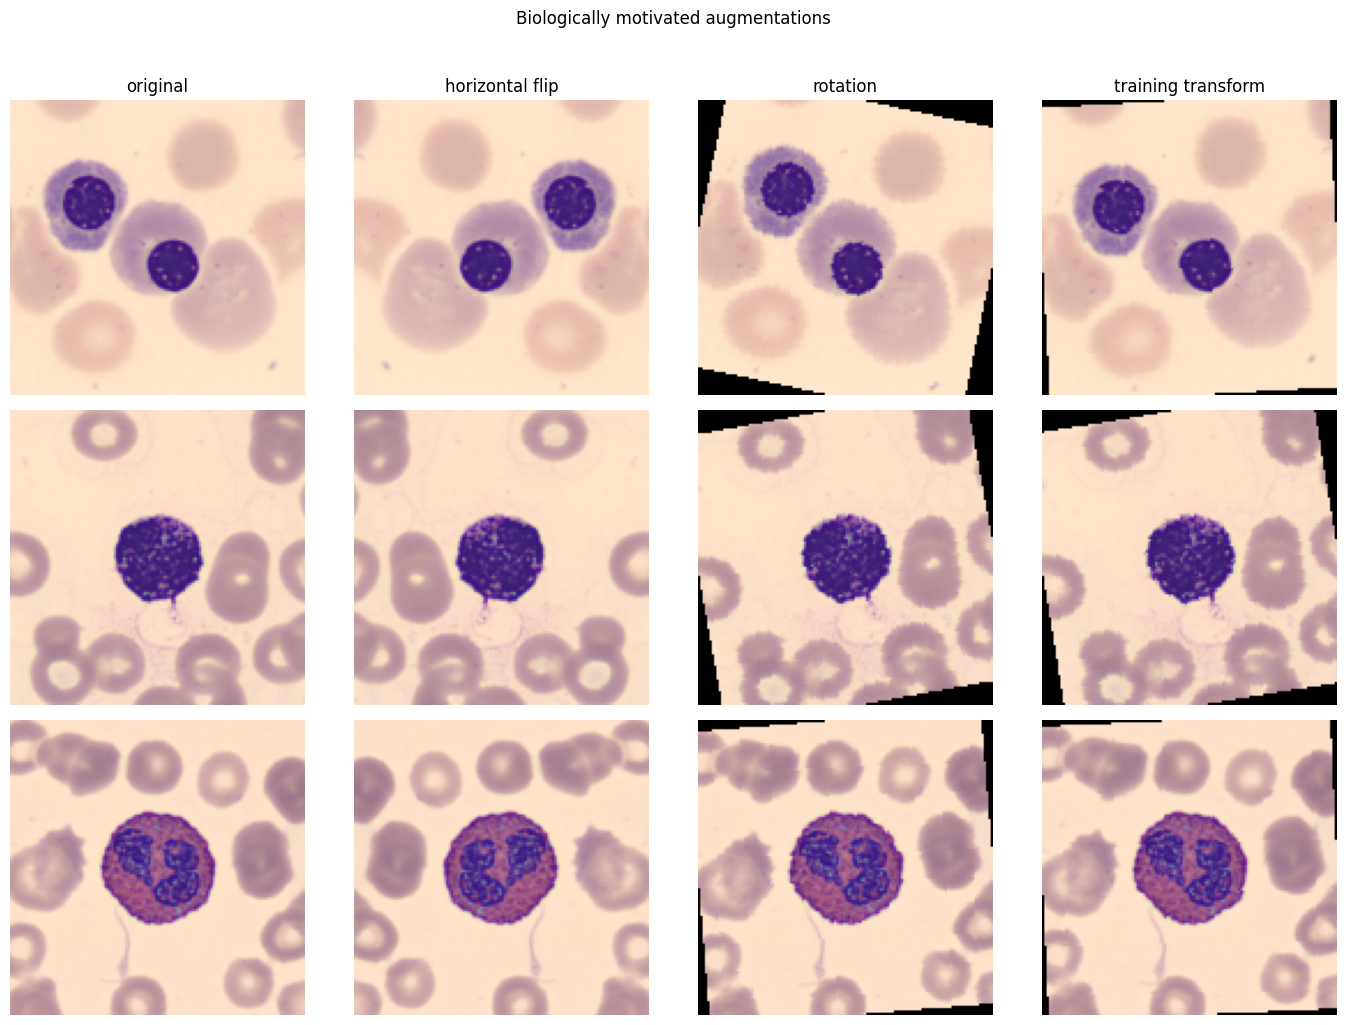

In [ ]:
plain_train_transform = eval_transform
augmented_train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
])


def tensor_for_display(tensor):
    return tensor.detach().cpu().permute(1, 2, 0).clamp(0, 1).numpy()


if classification_ready and SHOW_PLOTS:
    preview_indices = train_indices[:3]
    preview_transforms = {
        'original': plain_train_transform,
        'horizontal flip': transforms.Compose([
            transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
            transforms.RandomHorizontalFlip(p=1.0),
            transforms.ToTensor(),
        ]),
        'rotation': transforms.Compose([
            transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
            transforms.RandomRotation(15),
            transforms.ToTensor(),
        ]),
        'training transform': augmented_train_transform,
    }
    figure, axes = plt.subplots(len(preview_indices), len(preview_transforms), figsize=(14, 10), squeeze=False)
    for row, index in enumerate(preview_indices):
        image_path, label = image_dataset.samples[int(index)]
        with Image.open(image_path) as source_image:
            source_image = source_image.convert('RGB')
            for column, (name, transform) in enumerate(preview_transforms.items()):
                axes[row, column].imshow(tensor_for_display(transform(source_image)))
                axes[row, column].axis('off')
                if row == 0:
                    axes[row, column].set_title(name)
        axes[row, 0].set_ylabel(CLASS_NAMES[int(label)], rotation=90, fontsize=10)
    figure.suptitle('Biologically motivated augmentations', y=1.02)
    plt.tight_layout()
    plt.show()


In [ ]:
def make_train_loader(transform):
    source = datasets.ImageFolder(classification_root, transform=transform)
    return DataLoader(Subset(source, train_indices), batch_size=BATCH_SIZE, shuffle=True, num_workers=0)


augmentation_rows = []
if classification_ready and RUN_EXPENSIVE:
    for name, transform in [
        ('without augmentation', plain_train_transform),
        ('with flip+rotation', augmented_train_transform),
    ]:
        comparison_model = SimpleCNN(3, len(CLASS_NAMES), IMAGE_SIZE).to(DEVICE)
        comparison_loader = make_train_loader(transform)
        comparison_history, comparison_criterion = fit_classifier(
            comparison_model, comparison_loader, val_loader, COMPARISON_EPOCHS,
        )
        _, val_acc, _, _ = evaluate_classifier(comparison_model, val_loader, comparison_criterion, DEVICE)
        _, test_acc, _, _ = evaluate_classifier(comparison_model, test_loader, comparison_criterion, DEVICE)
        print(name, 'val=', val_acc, 'test=', test_acc)
        augmentation_rows.append({
            'model': f'SimpleCNN {name}',
            'change': name,
            'parameters': count_parameters(comparison_model),
            'epochs': COMPARISON_EPOCHS,
            'val_accuracy': val_acc,
            'test_accuracy': test_acc,
        })
else:
    print('Augmentation comparison skipped.')


01 | train=0.590 | val=0.753
02 | train=0.811 | val=0.826
03 | train=0.868 | val=0.883
04 | train=0.892 | val=0.891
05 | train=0.914 | val=0.904
06 | train=0.927 | val=0.885
07 | train=0.937 | val=0.888
08 | train=0.943 | val=0.905
09 | train=0.951 | val=0.892
10 | train=0.955 | val=0.894
without augmentation val= 0.8935049736688122 test= 0.8888888888888888
01 | train=0.561 | val=0.708
02 | train=0.765 | val=0.797
03 | train=0.828 | val=0.844
04 | train=0.854 | val=0.878
05 | train=0.867 | val=0.879
06 | train=0.878 | val=0.876
07 | train=0.884 | val=0.895
08 | train=0.892 | val=0.894
09 | train=0.893 | val=0.899
10 | train=0.900 | val=0.905
with flip+rotation val= 0.9052077238150965 test= 0.8906432748538011


## 10. Metrics table

All rows below share the same stratified split (`RANDOM_STATE=221026`). Differences are therefore due to the architecture or the augmentation, not to resampling the data.


In [ ]:
metrics_rows = []
if baseline_row is not None:
    metrics_rows.append(baseline_row)
if variant_row is not None:
    metrics_rows.append(variant_row)
metrics_rows.extend(augmentation_rows)
metrics_table = pd.DataFrame(metrics_rows)
if len(metrics_table):
    display(metrics_table)
    metrics_table.to_csv(WEEK7_ROOT / 'homework' / 'classification_metrics.csv', index=False)
    print('Saved:', WEEK7_ROOT / 'homework' / 'classification_metrics.csv')
else:
    print('No metrics yet. Run the training cells with RUN_EXPENSIVE=True.')


## Report answers (classification)

Fill these after the cells above have run. They map to homework questions 1, 2 and 6.

**1. What image, annotation, and split checks were necessary before modelling?**

- Image checks: ...
- Class-balance checks: ...
- Split checks: stratified split with `RANDOM_STATE=221026`; class counts in train/val/test were inspected.

**2. Which CNN change or augmentation improved classification, and how do you know it was not caused by a different split?**

- Best setting: ...
- Evidence: same `train_indices` / `val_indices` / `test_indices` for every run; only architecture or augmentation changed.

**6. What information would be needed to compare classification fairly across biological experiments?**

- Same staining / magnification / sensor bit depth, documented class definitions, patient- or well-level splits (not a random image split if several images come from the same field of view), and repeated seeds with uncertainty.
